In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression ,Ridge, Lasso
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [3]:
df=pd.read_csv('cleaned_houses.csv')
print(df.head())
print(df.head())
print(df.info())


       area  bedrooms  bathrooms  finishing     floor    price
0 -1.546882 -0.633507  -0.302369   1.259447  1.268552  2061000
1  0.951989  0.214940  -0.302369  -0.793999 -1.246199  4230000
2  0.508641  1.063387   1.476270  -0.793999 -1.246199  3995000
3 -0.277294 -1.481954  -1.191688   1.259447  1.268552  2824000
4 -0.297446 -0.633507  -1.191688  -0.793999  0.430302  3079000
       area  bedrooms  bathrooms  finishing     floor    price
0 -1.546882 -0.633507  -0.302369   1.259447  1.268552  2061000
1  0.951989  0.214940  -0.302369  -0.793999 -1.246199  4230000
2  0.508641  1.063387   1.476270  -0.793999 -1.246199  3995000
3 -0.277294 -1.481954  -1.191688   1.259447  1.268552  2824000
4 -0.297446 -0.633507  -1.191688  -0.793999  0.430302  3079000
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   area       150 non-null    float64
 1   bedrooms   150 non-null   

In [6]:
X = df.drop(columns=['price'])
y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
model=LinearRegression()
model.fit(x_train, y_train)
y_pred=model.predict(x_test)

In [14]:
print("\ntrain R2 score:", model.score(x_train, y_train))#to check how well the model fits the training data
print("Test R2 score:", model.score(x_test, y_test))#to check how well the model fits the testing data
print(" MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred,)**0.5)
print("MAE:", mean_absolute_error(y_test, y_pred))


train R2 score: 0.9809156699589161
Test R2 score: 0.9813572714011016
 MSE: 21546814974.85753
RMSE: 146788.3339194826
MAE: 118076.99336259157


In [18]:
print('\n intercept:', model.intercept_)
for name,coef in zip(X.columns, model.coef_):
    print(f"{name}: {round(coef, 2)}")


 intercept: 3451239.900708766
area: 751111.7
bedrooms: 203135.62
bathrooms: 97559.87
finishing: -211948.42
floor: 54992.69


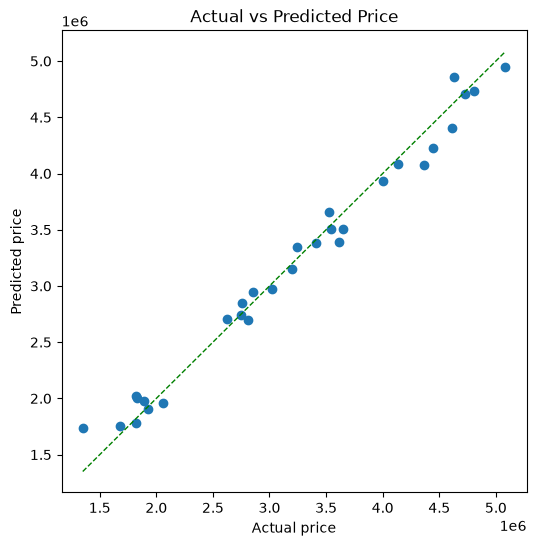

In [26]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--', color='green', lw=1)
plt.xlabel('Actual price')
plt.ylabel('Predicted price')
plt.title('Actual vs Predicted Price')
plt.show()


In [31]:
X_small_train, X_small_test, y_small_train, y_small_test = train_test_split(X, y, test_size=30, random_state=42)
ploy=PolynomialFeatures(degree=3,include_bias=False)
X_small_train_poly=ploy.fit_transform(X_small_train)
X_small_test_poly=ploy.transform(X_small_test)

print("features after polynomial transformation:", X_small_train_poly.shape[1])




features after polynomial transformation: 55


In [34]:
ploy_scaler=StandardScaler()
X_small_train_poly_scaled=ploy_scaler.fit_transform(X_small_train_poly) 
X_small_test_poly_scaled=ploy_scaler.transform(X_small_test_poly)

In [35]:
models = {
    "linear(overfitting)": LinearRegression(),
    "lasso l1": Lasso(alpha=5000 , max_iter=1000000),
    "ridge l2":Ridge(alpha=10)
}
train_scores, test_scores = {}, {}

print("overfitting vs regularization")
print("-"*55)



for name, m in models.items():
    m.fit(X_small_train_poly_scaled, y_small_train)
    train_scores[name] = m.score(X_small_train_poly_scaled, y_small_train)
    test_scores[name] = m.score(X_small_test_poly_scaled, y_small_test)
    print(f"{name}: Train Score = {train_scores[name]:.4f}, Test Score = {test_scores[name]:.4f}")


overfitting vs regularization
-------------------------------------------------------
linear(overfitting): Train Score = 0.9862, Test Score = 0.9742
lasso l1: Train Score = 0.9837, Test Score = 0.9802
ridge l2: Train Score = 0.9820, Test Score = 0.9718
